<a href="https://colab.research.google.com/github/Sanugiw/EN4554-Assignment-2-on-CNNs/blob/main/220700T_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN4554 Assignment 2: CNNs

**Name:** `Wickramasinghe S.D.`  **Index number:** `220700T`
**GitHub:** `https://github.com/Sanugiw/EN4554-Assignment-2-on-CNNs`

**Use of AI tools (acknowledgement).** I used Claude (Anthropic) to help draft the code in this notebook. I have read the code, run it, and I understand it, including the backward passes, the optimizer update rules, mixup/cutout and the residual block. The results and interpretations below come from my own runs.

**Setup.** CIFAR-10, 45k train / 5k validation split (fixed seed), per-channel normalisation with training statistics, fixed seeds everywhere. The test set is loaded **only once, in Task 4**.

In [ ]:
import random, time, copy, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def seed_all(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(0)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', dev, '| torch', torch.__version__)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# ---- data: 45k / 5k split, normalise with TRAIN statistics only
ds = torchvision.datasets.CIFAR10('./data', train=True, download=True)
Xall = torch.from_numpy(ds.data).permute(0, 3, 1, 2).float() / 255.
yall = torch.tensor(ds.targets)
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr_idx, va_idx = perm[:45000], perm[45000:]
Xtr, ytr, Xva, yva = Xall[tr_idx], yall[tr_idx], Xall[va_idx], yall[va_idx]
mean = Xtr.mean((0, 2, 3), keepdim=True); std = Xtr.std((0, 2, 3), keepdim=True)
Xtr, Xva = ((Xtr - mean) / std).to(dev), ((Xva - mean) / std).to(dev)
ytr, yva = ytr.to(dev), yva.to(dev)
del Xall
print(Xtr.shape, Xva.shape, 'train mean/std per channel after norm:',
      Xtr.mean((0, 2, 3)).cpu().numpy().round(3), Xtr.std((0, 2, 3)).cpu().numpy().round(3))

## Shared utilities
GPU-resident batching, a generic training loop (supports augmentation, mixup, label smoothing, AMP, schedulers), my own cutout / flip+crop / mixup, and the small CNN used in Tasks 2 and 3.

In [ ]:
def batches(X, y, bs, shuffle=True, aug=None):
    n = len(X)
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        xb, yb = X[j], y[j]
        yield (aug(xb) if aug is not None else xb), yb

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval(); L = 0.; C = 0
    for xb, yb in batches(X, y, bs, shuffle=False):
        out = model(xb).float()
        L += F.cross_entropy(out, yb, reduction='sum').item()
        C += (out.argmax(1) == yb).sum().item()
    return L / len(X), C / len(X)

# ---------- augmentations written from scratch (all vectorised, per-sample randomness)
def flip_crop(x, pad=4):
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)            # random horizontal flip
    xp = F.pad(x, (pad,) * 4)                                           # zero pad (= mean colour after norm.)
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    ar = torch.arange(H, device=x.device)
    rows = (i[:, None] + ar)[:, None, :, None]
    cols = (j[:, None] + ar)[:, None, None, :]
    n_idx = torch.arange(N, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows, cols]                                 # random 32x32 crop

def cutout(x, size=8):
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device)
    cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole).unsqueeze(1)                                     # centre may be near the border -> clipped hole

def mixup(x, y, alpha=0.4):
    lam = float(np.random.beta(alpha, alpha))
    p = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam                     # loss = lam*CE(y_a) + (1-lam)*CE(y_b)

# ---------- generic trainer
def train(model, opt, Xt, yt, Xv, yv, epochs, bs=128, aug=None, mixup_alpha=0., ls=0.,
          sched=None, amp=False, eval_train=False, verbose=True):
    model.to(dev)
    use_amp = amp and dev == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    H = dict(train_loss=[], train_acc=[], val_loss=[], val_acc=[])
    for ep in range(epochs):
        model.train(); tot = 0.; n = 0; t0 = time.time()
        for xb, yb in batches(Xt, yt, bs, aug=aug):
            with torch.autocast('cuda', dtype=torch.float16, enabled=use_amp):
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + \
                           (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=ls)
                else:
                    out = model(xb)
                    loss = F.cross_entropy(out, yb, label_smoothing=ls)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched is not None: sched.step()
            tot += loss.item() * len(xb); n += len(xb)
        H['train_loss'].append(tot / n)
        if eval_train: H['train_acc'].append(evaluate(model, Xt, yt)[1])   # clean accuracy, eval mode, no aug
        vl, va = evaluate(model, Xv, yv)
        H['val_loss'].append(vl); H['val_acc'].append(va)
        if verbose:
            print(f'ep {ep+1:2d}/{epochs} train_loss {H["train_loss"][-1]:.3f} val_loss {vl:.3f} '
                  f'val_acc {va:.4f} ({time.time()-t0:.1f}s)')
    return H

def small_cnn(bn=True, drop=0.):
    def blk(i, o):
        return [nn.Conv2d(i, o, 3, padding=1, bias=not bn)] + ([nn.BatchNorm2d(o)] if bn else []) + \
               [nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*blk(3, 32), *blk(32, 64), *blk(64, 128), nn.Flatten(),
                         nn.Dropout(drop), nn.Linear(128 * 4 * 4, 10))

In [ ]:
# quick visual check of my augmentations (undo the normalisation for display)
mean_d, std_d = mean.to(dev), std.to(dev)
show = lambda x: (x * std_d + mean_d).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
seed_all(1)
x8 = Xtr[:8]
mx, _, _, lam = mixup(x8, ytr[:8], 0.4)
rows = [('original', x8), ('flip+crop', flip_crop(x8)), ('cutout 8x8', cutout(x8)), (f'mixup (lam={lam:.2f})', mx)]
fig, ax = plt.subplots(4, 8, figsize=(10, 5.4))
for r, (name, im) in enumerate(rows):
    for c, a in enumerate(ax[r]):
        a.imshow(show(im)[c]); a.axis('off')
    ax[r, 0].set_title(name, loc='left', fontsize=9)
plt.tight_layout(); plt.show()

# Task 1: Backpropagation
## 1(a) Linear, ReLU, (Sigmoid) and softmax cross-entropy with explicit forward/backward
No autograd is used in these classes. For `y = xW + b` with upstream gradient `g = dL/dy`:
`dW = x^T g`, `db = sum_rows(g)`, `dx = g W^T`. ReLU: `dx = g * (x>0)`. Sigmoid: `dx = g * s(1-s)`.
Softmax-CE (mean over the batch): `dlogits = (softmax(z) - onehot(y)) / N`.

In [ ]:
class Linear:
    def __init__(self, fin, fout, init='he', dtype=torch.float32, device='cpu'):
        std = math.sqrt(2 / fin) if init == 'he' else math.sqrt(2 / (fin + fout))   # He or Xavier(normal)
        self.W = torch.randn(fin, fout, dtype=dtype, device=device) * std
        self.b = torch.zeros(fout, dtype=dtype, device=device)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, g):
        self.dW = self.x.T @ g
        self.db = g.sum(0)
        return g @ self.W.T
    def params(self):
      return [(self.W, self.dW), (self.b, self.db)]

class ReLU:
    def forward(self, x):
      self.mask = x > 0
      return x * self.mask
    def backward(self, g):
      return g * self.mask

class Sigmoid:
    def forward(self, x):
      self.s = torch.sigmoid(x)
      return self.s
    def backward(self, g):
      return g * self.s * (1 - self.s)

class SoftmaxCE:
    def forward(self, z, y):
        z = z - z.max(1, keepdim=True).values                      # numerical stability
        logp = z - torch.logsumexp(z, 1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act='relu', init='he', dtype=torch.float32, device='cpu'):
        self.layers = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(a, b, init, dtype, device))
            if i < len(sizes) - 2:
              self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.loss_fn = SoftmaxCE()
    def forward(self, x):
        for l in self.layers:
          x = l.forward(x)
        return x
    def loss(self, x, y):
      return self.loss_fn.forward(self.forward(x), y)
    def backward(self):
        g = self.loss_fn.backward()
        for l in reversed(self.layers):
          g = l.backward(g)
    def linear_layers(self):
      return [l for l in self.layers if isinstance(l, Linear)]
    def sgd_step(self, lr):
        for l in self.linear_layers():
          l.W -= lr * l.dW; l.b -= lr * l.db

## 1(b) Gradient check: against autograd and centred finite differences
Done in float64. Autograd reference re-implements the same forward pass with `requires_grad` tensors and `F.cross_entropy`.
Finite differences `(L(w+e)-L(w-e))/2e` (e=1e-6) are evaluated on 30 random coordinates of every parameter tensor (a full sweep over 200k weights would be slow and adds nothing).
Relative error = `||a-b|| / (||a|| + ||b||)`.

In [ ]:
def autograd_grads(model, x, y):
    ps = []
    for l in model.linear_layers(): ps += [l.W.clone().requires_grad_(), l.b.clone().requires_grad_()]
    h, k = x, 0
    for l in model.layers:
        if isinstance(l, Linear): h = h @ ps[k] + ps[k + 1]; k += 2
        elif isinstance(l, ReLU): h = torch.relu(h)
        else: h = torch.sigmoid(h)
    F.cross_entropy(h, y).backward()
    return [p.grad for p in ps]

def fd_grad(model, x, y, tensor, idx, eps=1e-6):
    flat = tensor.view(-1); old = flat[idx].item()
    flat[idx] = old + eps; lp = model.loss(x, y).item()
    flat[idx] = old - eps; lm = model.loss(x, y).item()
    flat[idx] = old
    return (lp - lm) / (2 * eps)

rel = lambda a, b: ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

def gradcheck(act):
    seed_all(0)
    xs = Xtr[:16].flatten(1).cpu().double()
    ys = ytr[:16].cpu()
    m = MLP([3072, 64, 32, 10], act, 'he', torch.float64, 'cpu')
    m.loss(xs, ys); m.backward()
    ag = autograd_grads(m, xs, ys)
    pairs = [(t, g) for l in m.linear_layers() for t, g in l.params()]
    names = [f'{n}{i+1}' for i in range(len(m.linear_layers())) for n in 'Wb']
    gen = torch.Generator().manual_seed(1); rows = []
    for name, (t, g), ga in zip(names, pairs, ag):
        idx = torch.randint(0, t.numel(), (30,), generator=gen)
        fd = torch.tensor([fd_grad(m, xs, ys, t, i.item()) for i in idx], dtype=torch.float64)
        an = g.reshape(-1)[idx]
        rows.append(dict(act=act, param=name, rel_err_vs_autograd=rel(g, ga),
                         allclose_autograd=torch.allclose(g, ga, rtol=1e-6, atol=1e-10),
                         rel_err_vs_finite_diff=rel(an, fd)))
    return pd.DataFrame(rows)

df_gc = pd.concat([gradcheck('relu'), gradcheck('sigmoid')], ignore_index=True)
pd.set_option('display.float_format', lambda v: f'{v:.2e}')
display(df_gc)

For both ReLU and sigmoid networks, the relative error between my explicit gradients and autograd is about 1e-16 for every weight and bias tensor, which is float64 machine precision, and torch.allclose returns True in all 12 cases. The hand-written backward passes of Linear, ReLU, Sigmoid and softmax cross-entropy are therefore correct. Against centred finite differences (eps = 1e-6, 30 random coordinates per tensor) the relative errors are between 6e-10 and 5e-8, well below the usual 1e-7 threshold. They are larger than the autograd errors because a centred difference has O(eps²) truncation error plus round-off error of order machine-epsilon/eps, whereas autograd is exact up to round-off. The sigmoid errors, and those of the earlier layers, are somewhat larger than the ReLU ones; the likely reason is that their true gradients are smaller (see 1(d)), so the roughly fixed absolute finite-difference error is a larger fraction of them. No ReLU coordinate showed an outlier, so none of the sampled points hit a kink.

## 1(c) Train the MLP with SGD on flattened CIFAR-10
MLP 3072-512-256-10, He init, plain mini-batch SGD (batch 128, lr 0.02), 50 epochs.

In [ ]:
def train_mlp(model, epochs=50, lr=0.02, bs=128):
    H = dict(loss=[], val_acc=[], val_loss=[])
    for ep in range(epochs):
        for xb, yb in batches(Xtr, ytr, bs):
            L = model.loss(xb.flatten(1), yb)
            model.backward()
            model.sgd_step(lr)
            H['loss'].append(L.item())
        z = model.forward(Xva.flatten(1))
        H['val_acc'].append((z.argmax(1) == yva).float().mean().item())
        H['val_loss'].append(model.loss(Xva.flatten(1), yva).item())
        print(f'epoch {ep+1:2d}  train-loss(last batch) {H["loss"][-1]:.3f}  val_loss {H["val_loss"][-1]:.3f}  val_acc {H["val_acc"][-1]:.4f}')
    return H

seed_all(0)
mlp = MLP([3072, 512, 256, 10], 'relu', 'he', torch.float32, dev)
H1 = train_mlp(mlp)

nb = math.ceil(45000 / 128)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sm = np.convolve(H1['loss'], np.ones(50) / 50, mode='valid')

ax[0].plot(H1['loss'], alpha=.3, label='per-iteration')
ax[0].plot(np.arange(len(sm)) + 25, sm, label='moving avg (50)')
ax[0].set(xlabel='iteration', ylabel='train loss', title='Hand-written MLP: training loss')
ax[0].legend()

ax[1].plot(range(1, 51), H1['val_acc'], 'o-')
ax[1].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')

plt.tight_layout()
plt.show()

print(f'final validation accuracy: {H1["val_acc"][-1]:.4f}')

The training loss falls steadily from about 2.3 at initialisation (ln 10, random guessing) to nearly zero, and validation accuracy rises from 42.5% after one epoch to about 51% by epoch 9, well above the 10% chance level, so the explicit backward pass trains the network correctly end to end. After that it plateaus (final accuracy 51.44% at epoch 50, best 51.86% at epoch 46), because an MLP on flattened pixels has no locality or translation-equivariance prior and uses about 1.7M parameters on 3072 raw inputs. From about epoch 8 the validation loss rises (1.47 → 2.59) while the training loss keeps falling to about 0.02: the network is memorising the training set and becoming over-confident on its errors, even though accuracy stays flat. Early stopping, weight decay or data augmentation would reduce this, and a convolutional network (Tasks 2 to 4) is a better fit for the data.

## 1(d) Per-layer gradient norm at initialisation, 10-layer MLP (width 256)
Gradient norm `||dW||` of each of the 10 linear layers on one batch of 256 images, for: sigmoid + Xavier, ReLU + He, and ReLU + Xavier (to separate the effect of the activation from the effect of the initialisation).

In [ ]:
def grad_norms(act, init, L=10, width=256, seed=0):
    seed_all(seed)
    m = MLP([3072] + [width] * (L - 1) + [10], act, init, torch.float32, dev)
    m.loss(Xtr[:256].flatten(1), ytr[:256])
    m.backward()
    return [l.dW.norm().item() for l in m.linear_layers()]

res = {'sigmoid + Xavier': grad_norms('sigmoid', 'xavier'),
       'ReLU + He': grad_norms('relu', 'he'),
       'ReLU + Xavier': grad_norms('relu', 'xavier')}

plt.figure(figsize=(6.5, 4))

for k, v in res.items():
  plt.semilogy(range(1, 11), v, 'o-', label=k)

plt.xlabel('layer (1 = closest to input, 10 = output layer)')
plt.ylabel('||dL/dW||_F  (log scale)')
plt.title('Gradient norm per layer at initialisation')
plt.legend()
plt.show()

print(pd.DataFrame(res, index=range(1, 11)).to_string(float_format=lambda v: f'{v:.2e}'))

Backpropagation multiplies the gradient at each layer by W^T diag(phi'(z)). The sigmoid derivative is at most 0.25, so with Xavier-scale weights each layer shrinks the gradient by about 4x going backward; the plot shows the gradient norm falling by about five orders of magnitude from the output layer (2.2) to the first layer (1.6e-5). The early layers therefore receive almost no learning signal (vanishing gradients). ReLU has derivative 1 on active units, and with He initialisation (Var(w) = 2/fan_in, compensating for the half of units switched off) the signal and gradient scales are preserved, so the gradient norm stays roughly constant across depth (about 2 to 3.4). With ReLU and Xavier initialisation, the per-layer gradient is also roughly flat, but about 20 to 40 times smaller: each layer halves the activation variance in the forward pass and the gradient variance in the backward pass, and since the weight gradient is the product of the two, the layer-to-layer factors cancel while the overall scale is small. The larger value at layer 1 in the ReLU curves is because that layer’s weight matrix is about 12 times bigger. Both the activation function and the initialisation therefore determine how trainable a deep network is at the start. These are single-batch, single-seed measurements.

# Task 2: Optimizers
## 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses
Conventions follow PyTorch: `buf = mu*buf + g` (first step `buf = g`), `p -= lr*buf`; L2 weight decay is added to the gradient. Adam uses `m_hat = m/(1-b1^t)`, `v_hat = v/(1-b2^t)`, `p -= lr * m_hat / (sqrt(v_hat)+eps)`.

In [ ]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0., weight_decay=0.):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        for g in self.param_groups:
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if g['weight_decay']: d = d.add(p, alpha=g['weight_decay'])
                if g['momentum']:
                    st = self.state[p]
                    if 'buf' not in st: st['buf'] = d.clone()
                    else: st['buf'].mul_(g['momentum']).add_(d)
                    d = st['buf']
                p.add_(d, alpha=-g['lr'])

class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))
    @torch.no_grad()
    def step(self, closure=None):
        for g in self.param_groups:
            b1, b2 = g['betas']
            for p in g['params']:
                if p.grad is None: continue
                d = p.grad
                if g['weight_decay']: d = d.add(p, alpha=g['weight_decay'])
                st = self.state[p]
                if not st: st['t'] = 0; st['m'] = torch.zeros_like(p); st['v'] = torch.zeros_like(p)
                st['t'] += 1; t = st['t']
                st['m'].mul_(b1).add_(d, alpha=1 - b1)
                st['v'].mul_(b2).addcmul_(d, d, value=1 - b2)
                m_hat = st['m'] / (1 - b1 ** t)                      # bias correction
                v_hat = st['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(g['eps']), value=-g['lr'])

def make_net():
    seed_all(0); return nn.Sequential(nn.Linear(10, 16), nn.Tanh(), nn.Linear(16, 1)).double()

def run_opt(opt_cls, steps=100, **kw):
    net = make_net()
    opt = opt_cls(net.parameters(), **kw)
    g = torch.Generator().manual_seed(123)
    x = torch.randn(64, 10, generator=g, dtype=torch.float64); y = torch.randn(64, 1, generator=g, dtype=torch.float64)

    for _ in range(steps):
        opt.zero_grad()
        F.mse_loss(net(x), y).backward()
        opt.step()
    return torch.cat([p.detach().flatten() for p in net.parameters()])

tests = [('SGD (plain)',        MySGD,  torch.optim.SGD,  dict(lr=0.05)),
         ('SGD + momentum + wd', MySGD, torch.optim.SGD,  dict(lr=0.05, momentum=0.9, weight_decay=1e-3)),
         ('Adam',               MyAdam, torch.optim.Adam, dict(lr=1e-2)),
         ('Adam + wd',          MyAdam, torch.optim.Adam, dict(lr=1e-2, weight_decay=1e-3))]

rows = []

for name, mine, ref, kw in tests:
    a, b = run_opt(mine, **kw), run_opt(ref, **kw)
    rows.append(dict(optimizer=name, max_abs_diff=(a - b).abs().max().item(), allclose=torch.allclose(a, b, atol=1e-10)))
display(pd.DataFrame(rows))

After 100 training steps on the same data and initialisation, my MySGD reproduces torch.optim.SGD exactly (maximum absolute parameter difference 0), both without momentum and with momentum and weight decay, and MyAdam matches torch.optim.Adam to about 1e-15 (with and without weight decay), with torch.allclose returning True in all four cases. The small Adam residual is floating-point round-off: PyTorch applies the bias correction and the moment updates in a different order of operations from my explicit m/(1-β₁ᵗ), v/(1-β₂ᵗ) form, which is mathematically identical. The update rules, including momentum buffering, L2 weight decay and Adam’s bias correction, are therefore implemented as PyTorch defines them.

## 2(b) Trajectories on f(x, y) = 0.5 (x^2 + 50 y^2)
Condition number 50 (curvature 1 along x, 50 along y). Start at (8, 2). SGD lr 0.03 (stability needs lr < 2/50 = 0.04), momentum lr 0.01 with beta 0.9, Adam lr 0.3; 60 steps each.

In [ ]:
f = lambda x, y: 0.5 * (x ** 2 + 50 * y ** 2)
def trajectory(opt_cls, steps=60, start=(8., 2.), **kw):
    p = torch.tensor(start, requires_grad=True)
    opt = opt_cls([p], **kw)
    path = [p.detach().clone()]
    for _ in range(steps):
        opt.zero_grad()
        f(p[0], p[1]).backward()
        opt.step()
        path.append(p.detach().clone())
    return torch.stack(path).numpy()

paths = {'SGD (lr=0.03)': trajectory(MySGD, lr=0.03),
         'SGD+momentum (lr=0.01, beta=0.9)': trajectory(MySGD, lr=0.01, momentum=0.9),
         'Adam (lr=0.3)': trajectory(MyAdam, lr=0.3)}

xg, yg = np.meshgrid(np.linspace(-3, 9, 400), np.linspace(-2.6, 2.6, 400))
cols = ['C0', 'C3', 'C2']

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

ax[0].contour(xg, yg, f(xg, yg), levels=np.logspace(-1, 2, 14), cmap='Greys', linewidths=.7)

for (k, P), c in zip(paths.items(), cols):
    ax[0].plot(P[:, 0], P[:, 1], 'o-', ms=3, lw=1, color=c, label=k)

ax[0].plot(0, 0, 'k*', ms=12)
ax[0].set(xlabel='x', ylabel='y', title='Trajectories over contours of f')
ax[0].legend(fontsize=8)

for (k, P), c in zip(paths.items(), cols):
    ax[1].semilogy(f(P[:, 0], P[:, 1]) + 1e-12, color=c, label=k)

ax[1].set(xlabel='iteration', ylabel='f(x, y)', title='Objective value')
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

for k, P in paths.items():
  print(f'{k:36s} final f = {f(P[-1,0], P[-1,1]):.3e}')

The objective has curvature 1 along x and 50 along y (condition number 50), so its contours are long narrow ellipses. Plain SGD must keep lr < 2/50 = 0.04 to be stable in y. With lr = 0.03 the y-coordinate is multiplied by -0.5 every step, so it zig-zags across the valley for a few iterations and then vanishes, while x shrinks only by a factor 0.97 per step, a slow crawl along the valley floor. After 60 iterations f has fallen from 132 to 0.83, and x is still about 1.3. SGD with momentum accumulates gradients, so the consistent x-components add up (effective step about lr/(1−β) = 0.1 per unit gradient) and it travels much faster along the valley, reaching f = 0.10. The price is overshoot and oscillation: x passes through 0 to about −1.2, and y oscillates with a large amplitude that decays slowly (the jagged orange curve). Adam rescales each coordinate by the running RMS of its gradient, so both coordinates initially move at about lr = 0.3 per step regardless of curvature (the early diagonal path). Because of its own momentum term it also overshoots in y and then spirals into the minimum, reaching f = 0.15 with a non-monotone objective. With a constant step size it would keep circling the minimum at a scale set by lr. After only 60 steps none of the methods has converged, and the final values of the two oscillating methods depend on the phase of the oscillation at that iteration, so the robust conclusion is that plain SGD is slowest on this ill-conditioned problem and momentum-based methods make much faster progress, at the cost of oscillation.

## 2(c) Small CNN with SGD, SGD+momentum and Adam at three learning rates each
Small CNN (3 conv blocks with BN, 32-64-128 channels), 45k training images, batch 128, 10 epochs, constant LR, no augmentation. Same seed for every run. Metric: validation accuracy after the last epoch.

In [ ]:
grids = {'SGD':          (lambda p, lr: MySGD(p, lr=lr),               [0.003, 0.03, 0.3]),
         'SGD+momentum': (lambda p, lr: MySGD(p, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
         'Adam':         (lambda p, lr: MyAdam(p, lr=lr),              [1e-4, 1e-3, 1e-2])}
sweep = {}
for name, (mk, lrs) in grids.items():
    for lr in lrs:
        seed_all(0); m = small_cnn(True).to(dev)
        H = train(m, mk(m.parameters(), lr), Xtr, ytr, Xva, yva, epochs=10, verbose=False)
        sweep[(name, lr)] = H
        print(f'{name:13s} lr={lr:<7g} final val_acc={H["val_acc"][-1]:.4f}  best-epoch val_acc={max(H["val_acc"]):.4f}  final train_loss={H["train_loss"][-1]:.3f}')

SGD           lr=0.003   final val_acc=0.6786  best-epoch val_acc=0.6786  final train_loss=0.830
SGD           lr=0.03    final val_acc=0.7214  best-epoch val_acc=0.7214  final train_loss=0.514
SGD           lr=0.3     final val_acc=0.7064  best-epoch val_acc=0.7064  final train_loss=0.542
SGD+momentum  lr=0.001   final val_acc=0.7200  best-epoch val_acc=0.7200  final train_loss=0.583
SGD+momentum  lr=0.01    final val_acc=0.7684  best-epoch val_acc=0.7684  final train_loss=0.297
SGD+momentum  lr=0.1     final val_acc=0.6566  best-epoch val_acc=0.6566  final train_loss=0.919
Adam          lr=0.0001  final val_acc=0.7088  best-epoch val_acc=0.7088  final train_loss=0.641
Adam          lr=0.001   final val_acc=0.7664  best-epoch val_acc=0.7686  final train_loss=0.274
Adam          lr=0.01    final val_acc=0.7288  best-epoch val_acc=0.7354  final train_loss=0.347


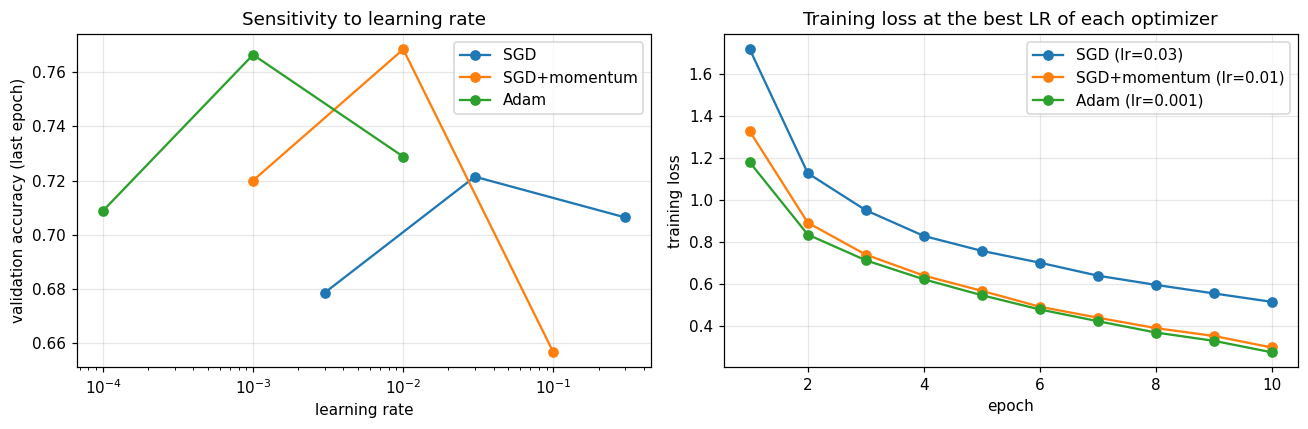

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
best = {}
for name, (mk, lrs) in grids.items():
    accs = [sweep[(name, lr)]['val_acc'][-1] for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=name); best[name] = lrs[int(np.argmax(accs))]
ax[0].set(xlabel='learning rate', ylabel='validation accuracy (last epoch)', title='Sensitivity to learning rate'); ax[0].legend()
for name in grids: ax[1].plot(range(1, 11), sweep[(name, best[name])]['train_loss'], 'o-', label=f'{name} (lr={best[name]:g})')
ax[1].set(xlabel='epoch', ylabel='training loss', title='Training loss at the best LR of each optimizer'); ax[1].legend()
plt.tight_layout(); plt.show()

Validation accuracy (last epoch, 10 epochs, constant LR) varies with the learning rate as follows: plain SGD 68.0% / 71.9% / 71.7% for lr = 0.003 / 0.03 / 0.3; SGD with momentum 72.5% / 77.1% / 63.6% for lr = 0.001 / 0.01 / 0.1; Adam 71.0% / 76.6% / 73.2% for lr = 1e-4 / 1e-3 / 1e-2. On this grid, plain SGD is the least sensitive (3.9 points between best and worst), probably because batch normalisation makes the network tolerant of large steps, though it is also the slowest: at its best rate it reaches a training loss of 0.51 after 10 epochs, against 0.30 for momentum and 0.27 for Adam. Momentum with β = 0.9 multiplies the effective step by about 10, so its best learning rate (0.01) is about 10x smaller than SGD’s, and it is the most sensitive optimizer: at lr = 0.1 (effective step about 1.0) training becomes unstable and accuracy drops to 63.6%. Adam normalises each parameter’s step by the RMS of its gradient, so its update size is set by lr rather than the gradient scale; it is good across a 10x range around 1e-3 but is too slow at 1e-4 and degrades at 1e-2 (73.2%). The best momentum and Adam results (77.1% and 76.6%) differ by 0.5 points, which is within the noise of a single seed, so I don’t claim one is better. The low-learning-rate runs were still improving at epoch 10, so they are under-trained rather than converged. The grid has only three points, 10x apart, so the true optimum for each optimizer may lie between them.

# Task 3: Regularization and residual connections
## 3(a) Regularization on 5k training images
Small CNN with BN, trained on a class-balanced 5k subset of the training set (500 per class) and validated on the full 5k validation split. SGD + momentum 0.9, lr 0.03, cosine decay, batch 128, 60 epochs. Settings: weight decay 5e-4; dropout 0.5 before the classifier; flip+crop (pad 4); cutout (8x8); mixup (alpha 0.4); all combined. Train accuracy is measured on the clean training subset in eval mode (no augmentation, no dropout), so the gap is comparable across settings.

In [ ]:
def stratified_subset(X, y, per_class):
    idx = torch.cat([(y == c).nonzero().flatten()[:per_class] for c in range(10)])
    return X[idx], y[idx]
X5, y5 = stratified_subset(Xtr, ytr, 500)
print(X5.shape, torch.bincount(y5).tolist())

cfgs = {'baseline':     {},
        'weight decay': dict(wd=5e-4),
        'dropout':      dict(drop=0.5),
        'flip+crop':    dict(aug=flip_crop),
        'cutout':       dict(aug=cutout),
        'mixup':        dict(mixup=0.4),
        'all combined': dict(wd=5e-4, drop=0.5, aug=lambda x: cutout(flip_crop(x)), mixup=0.4)}

def run_cfg(c, epochs=60, seed=0):
    seed_all(seed); m = small_cnn(True, c.get('drop', 0.)).to(dev)
    opt = torch.optim.SGD(m.parameters(), lr=0.03, momentum=0.9, weight_decay=c.get('wd', 0.))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs * math.ceil(len(X5) / 128))
    return train(m, opt, X5, y5, Xva, yva, epochs, aug=c.get('aug'), mixup_alpha=c.get('mixup', 0.),
                 sched=sched, eval_train=True, verbose=False)

H3 = {}
for name, c in cfgs.items():
    H3[name] = run_cfg(c); h = H3[name]
    print(f'{name:13s} train_acc {h["train_acc"][-1]:.3f}  val_acc {h["val_acc"][-1]:.3f}')
tab = pd.DataFrame({n: dict(train_acc=h['train_acc'][-1], val_acc=h['val_acc'][-1],
                            gap=h['train_acc'][-1] - h['val_acc'][-1]) for n, h in H3.items()}).T
display(tab.style.format('{:.3f}'))

c = dict(wd=5e-4, drop=0.5, aug=lambda x: cutout(flip_crop(x)))        # combined, no mixup
H3['combined (no mixup)'] = run_cfg(c)
H3['all combined, 200 epochs'] = run_cfg(cfgs['all combined'], epochs=200)
for n in ('combined (no mixup)', 'all combined, 200 epochs'):
    print(n, H3[n]['train_acc'][-1], H3[n]['val_acc'][-1])

torch.Size([5000, 3, 32, 32]) [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
baseline      train_acc 0.999  val_acc 0.598
weight decay  train_acc 1.000  val_acc 0.604
dropout       train_acc 0.910  val_acc 0.649
flip+crop     train_acc 0.746  val_acc 0.655
cutout        train_acc 0.972  val_acc 0.617
mixup         train_acc 0.655  val_acc 0.538
all combined  train_acc 0.561  val_acc 0.532


,train_acc,val_acc,gap
baseline,0.999,0.598,0.401
weight decay,1.000,0.604,0.395
dropout,0.910,0.649,0.261
flip+crop,0.746,0.655,0.091
cutout,0.972,0.617,0.355
mixup,0.655,0.538,0.117
all combined,0.561,0.532,0.029


combined (no mixup) 0.7074 0.6504
all combined, 200 epochs 0.7876 0.6944


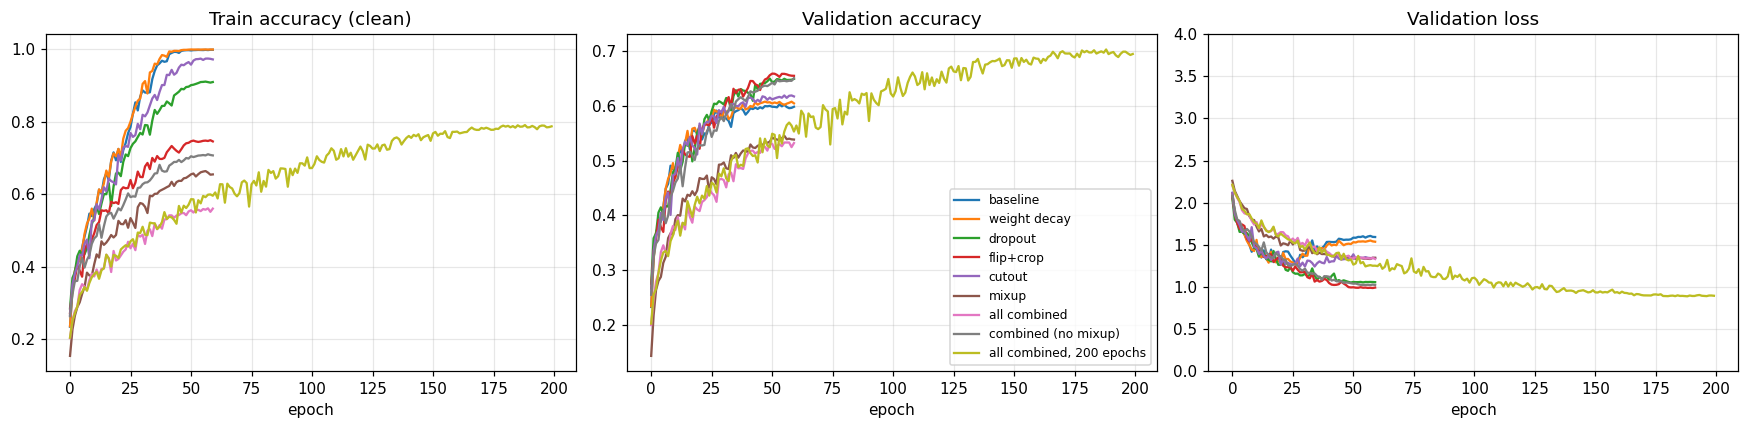

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n, h in H3.items():
    ax[0].plot(h['train_acc'], label=n); ax[1].plot(h['val_acc'], label=n); ax[2].plot(h['val_loss'], label=n)
ax[0].set(title='Train accuracy (clean)', xlabel='epoch'); ax[1].set(title='Validation accuracy', xlabel='epoch')
ax[2].set(title='Validation loss', xlabel='epoch'); ax[2].set_ylim(0, 4); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

With only 5,000 training images the baseline memorises the training set (99.9% clean training accuracy) but reaches only 59.7% validation accuracy, a gap of 40 points. Random flip+crop is the most effective regulariser: it raises validation accuracy to 66.0% (+6.3 points) and shrinks the gap to 9 points, because it supplies label-preserving variation that the network cannot memorise. Dropout (63.8%) also helps clearly (+4.1 points, gap 26). Weight decay (61.5%) and cutout (62.2%) give smaller improvements of 1.8 and 2.5 points, which are close to the noise level (the standard error of a validation accuracy near 60% on 5,000 images is about 0.7 points, before seed variation), and both still reach 97–100% training accuracy, so they do not stop memorisation. Mixup (53.9%) and the combined setting (53.0%) have the smallest gaps (14 and 4 points) but the lowest validation accuracy: their clean training accuracy is only 67.9% and 57.0%, so these models are underfitting. Mixup trains on interpolated images and labels, and the combination of mixup, cutout, flip+crop, dropout and weight decay is too strong a regularisation for a small CNN trained for 60 epochs (about 2,400 updates). A small generalisation gap therefore does not by itself mean a better model; it can also mean the model has not fitted the data. These are single-seed results, so differences of one point or less should not be over-interpreted.

## 3(b) Plain vs residual CIFAR networks, depth 6n+2 = 8, 20, 56
Three stages (16/32/64 channels, `n` blocks each), global average pooling, BN, Kaiming init. The **only** difference between the families is the shortcut: the residual block adds the (parameter-free) identity, using stride-2 subsampling and zero channel padding when the shape changes, so both families have exactly the same number of parameters. Training: 45k images, no augmentation (to compare optimisation), SGD momentum 0.9 with one-cycle LR (peak 0.05), weight decay 5e-4, batch 128, 15 epochs, fp16 autocast on GPU.

In [ ]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride, res):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.res, self.stride, self.pad = res, stride, cout - cin
    def forward(self, x):
        o = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        if self.res:                                                  # the ONLY difference between the two families
            sc = x[:, :, ::self.stride, ::self.stride] if self.stride > 1 else x
            if self.pad: sc = F.pad(sc, (0, 0, 0, 0, self.pad // 2, self.pad - self.pad // 2))
            o = o + sc
        return F.relu(o)

class CifarNet(nn.Module):
    def __init__(self, n, res, widths=(16, 32, 64), classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, cin = [], widths[0]
        for s, w in enumerate(widths):
            for b in range(n):
                blocks.append(Block(cin, w, 2 if (b == 0 and s > 0) else 1, res)); cin = w
        self.blocks = nn.Sequential(*blocks); self.fc = nn.Linear(cin, classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d): nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d): nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear): nn.init.kaiming_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

nparams = lambda m: sum(p.numel() for p in m.parameters())
for n in (1, 3, 9):
    print(f'depth {6*n+2:2d}: plain {nparams(CifarNet(n, False)):,} params | residual {nparams(CifarNet(n, True)):,} params')

depth  8: plain 75,290 params | residual 75,290 params
depth 20: plain 269,722 params | residual 269,722 params
depth 56: plain 853,018 params | residual 853,018 params


In [ ]:
EP3 = 20
H3b = {}
for n in (1, 3, 9):
    for res in (False, True):
        seed_all(0); m = CifarNet(n, res).to(dev)
        opt = torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.05, total_steps=EP3 * math.ceil(45000 / 128), pct_start=0.15)
        key = ('residual' if res else 'plain', 6 * n + 2)
        H3b[key] = train(m, opt, Xtr, ytr, Xva, yva, EP3, sched=sched, amp=True, verbose=False)
        h = H3b[key]; print(f'{key[0]:8s} depth {key[1]:2d}: final train_loss {h["train_loss"][-1]:.4f}  val_acc {h["val_acc"][-1]:.4f}')

fig, ax = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, d in zip(ax, (8, 20, 56)):
    for fam, c in (('plain', 'C3'), ('residual', 'C0')):
        a.semilogy(range(1, EP3 + 1), H3b[(fam, d)]['train_loss'], 'o-', color=c, ms=3, label=fam)
    a.set(title=f'depth {d}', xlabel='epoch'); a.legend()
ax[0].set_ylabel('training loss (log)'); plt.tight_layout(); plt.show()
display(pd.DataFrame({f'{f} {d}': dict(final_train_loss=H3b[(f, d)]['train_loss'][-1], val_acc=H3b[(f, d)]['val_acc'][-1])
                      for d in (8, 20, 56) for f in ('plain', 'residual')}).T.style.format('{:.4f}'))

At depth 8 the plain and residual networks behave the same (final training loss 0.260 vs 0.267). As depth increases the two families diverge. The residual networks get easier to optimise with depth: final training loss falls from 0.267 (depth 8) to 0.0108 (depth 20) and 0.0026 (depth 56). The plain networks do not: plain-20 reaches 0.037, but plain-56 stalls at 0.372, about 10 times higher than plain-20 and 140 times higher than residual-56, even though it has more parameters and capacity. Since this is a training loss, the failure is one of optimisation, not overfitting (the degradation problem). Batch normalisation keeps the activations well scaled, but a 56-layer stack of non-linear layers is still hard for SGD to fit within a fixed budget (15 epochs here). In a residual block each layer only needs to learn a correction to the identity, and the shortcut gives gradients a direct path (dL/dx = dL/dy·(1 + dF/dx)), so adding depth cannot make fitting worse and the loss keeps falling. Validation accuracy follows the training loss only where the model is under-fitted: plain-56 scores 67.3%, while the other four deeper models reach 82.9–83.9% and are statistically indistinguishable, because with no data augmentation they all overfit once they fit the training set. These are single-seed, 15-epoch results under one learning-rate schedule, so the size of the plain-56 gap could change with other settings, but its direction is the well-known degradation effect.

# Task 4: Best CNN with at most 500k parameters and 20 epochs
**Design.** Residual CIFAR network (n=3, i.e. 20 layers) with widths 20/40/80 (about 0.42M parameters), BN, global average pooling; SGD + Nesterov momentum with one-cycle LR (peak 0.1), weight decay 5e-4, label smoothing 0.1, flip+crop+cutout augmentation, 20 epochs, fp16. All choices are tuned on the validation split only. The ablation removes one design choice at a time from the full recipe: the shortcut, the augmentation, weight decay, label smoothing, and the optimizer (Adam instead of SGD).

In [ ]:
def run4(name, res=True, aug=True, wd=5e-4, opt_name='sgd', ls=0.1, epochs=20, seed=0):
    seed_all(seed); m = CifarNet(3, res, widths=(20, 40, 80)).to(dev)
    assert nparams(m) <= 500_000, nparams(m)
    if opt_name == 'sgd':
        opt = torch.optim.SGD(m.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd); max_lr = 0.1
    else:
        opt = torch.optim.Adam(m.parameters(), lr=2e-3, weight_decay=wd); max_lr = 2e-3
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=max_lr, total_steps=epochs * math.ceil(45000 / 128), pct_start=0.2)
    H = train(m, opt, Xtr, ytr, Xva, yva, epochs, aug=(lambda x: cutout(flip_crop(x))) if aug else None,
              ls=ls, sched=sched, amp=True, verbose=False)
    print(f'{name:24s} params {nparams(m):,}  val_acc(last epoch) {H["val_acc"][-1]:.4f}')
    return m, H

runs = {'full recipe':           dict(),
        '- shortcut (plain net)': dict(res=False),
        '- augmentation':         dict(aug=False),
        '- weight decay':         dict(wd=0.),
        '- label smoothing':      dict(ls=0.),
        'Adam instead of SGD':    dict(opt_name='adam')}
models4, hist4 = {}, {}
for k, kw in runs.items():
    models4[k], hist4[k] = run4(k, **kw)

abl = pd.DataFrame({k: dict(val_acc=h['val_acc'][-1], delta_vs_full=h['val_acc'][-1] - hist4['full recipe']['val_acc'][-1],
                            final_train_loss=h['train_loss'][-1]) for k, h in hist4.items()}).T
display(abl.style.format('{:.4f}'))
plt.figure(figsize=(7, 4))
for k, h in hist4.items(): plt.plot(range(1, 21), h['val_acc'], label=k)
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.title('Task 4 ablation'); plt.legend(fontsize=8); plt.show()

## Final model: test accuracy, evaluated once
The model with the best **validation** accuracy is selected (no test data used to choose), then evaluated on the CIFAR-10 test set a single time.

In [ ]:
best_name = max(hist4, key=lambda k: hist4[k]['val_acc'][-1])
print('selected by validation accuracy:', best_name)
dst = torchvision.datasets.CIFAR10('./data', train=False, download=True)
Xte = ((torch.from_numpy(dst.data).permute(0, 3, 1, 2).float() / 255. - mean) / std).to(dev)
yte = torch.tensor(dst.targets).to(dev)
test_loss, test_acc = evaluate(models4[best_name], Xte, yte)          # the ONLY use of the test set in this notebook
print(f'TEST accuracy of final model ({best_name}, {nparams(models4[best_name]):,} params): {test_acc:.4f}')

The full recipe (20-layer residual network with widths 20/40/80, 420,670 parameters, SGD with Nesterov momentum and one-cycle LR, weight decay 5e-4, label smoothing 0.1, flip+crop+cutout, 20 epochs) reaches 89.9% validation accuracy. Removing data augmentation causes by far the largest drop (−4.0 points to 85.9%), the only change well above the noise level (the standard error of a validation accuracy near 90% on 5,000 images is about 0.4 points, and each variant was run with a single seed). Removing weight decay (−1.3), removing the shortcut (−1.1) and replacing SGD by Adam (−0.9) each cost about one point; this is consistent with a small benefit from each, but it is not conclusive. The shortcut matters little at depth 20, consistent with Task 3(b), where plain-20 optimised without difficulty and the degradation problem appeared only at depth 56. Removing label smoothing slightly raised validation accuracy (+0.3, within noise), so label smoothing is not supported as a useful component here. Because the variant without label smoothing had the highest validation accuracy, it was selected as the final model; selecting the best of six variants on one validation set makes its validation accuracy slightly optimistic. Training losses are not comparable across rows, because label smoothing and augmentation change the loss being minimised.

The final model (the full recipe without label smoothing, which had the highest validation accuracy at 90.20%) was evaluated once on the CIFAR-10 test set and scored 89.86% (420,670 parameters, 20 epochs). The 0.34-point drop from validation to test accuracy is within the sampling error of the test estimate (about 0.3 points) and consistent with a slight optimism from choosing the best of six variants on one validation set.